# Unsupervised PCA — Gene-level vs Pathway-level × PDAC vs Healthy / Classical vs Basal-like

## Overview

This notebook tests whether pathway-level somatic mutation profiles contain separable cluster
structure for (a) PDAC versus healthy individuals (PvH) and (b) Classical versus Basal-like
PDAC subtypes (CvB). It compares gene-level and pathway-level binary feature representations
in a 2×2 design using an unsupervised pipeline (StandardScaler → PCA, 25 components → Ward
hierarchical clustering k=2), evaluated with the Silhouette score computed against true subtype
labels (−1 = worst separation, +1 = perfect separation). For PvH, 100 subagging draws are used
to account for variability in the 1000G healthy cohort; CvB uses a single deterministic run on
142 labelled TCGA patients. The notebook produces a 2×2 PCA scatter plot exported as
`figure_A_pca_2x2.{png,svg}`.

## Data

**Input**
- `merged_tcga_1000G.parquet` — merged somatic (TCGA-PAAD, `source == 'TCGA'`) and germline
  (1000 Genomes, `source == '1000G'`) mutations. Columns: `source`, `sample_id`, `gene_symbol`,
  `gene_name`, `am_pathogenicity`, `subtype`.
- `healthy_downsampled_bootstrap.parquet` — 100 pre-drawn bootstrap partitions of 1000G variant
  profiles (keyed by `bootstrap_id`).
- `reactome_hierarchy/` — Reactome flat files (`ReactomePathways.txt`,
  `ReactomePathwaysRelation.txt`, `ReactomePathways.gmt`); Hallmark gene sets fetched at runtime
  via GSEApy (`MSigDB_Hallmark_2020`).

**Processing**
- Exclude hypermutator patient (TMB > 500). Define CvB (142 labelled TCGA patients) and
  PvH full (167 PDAC + 3,202 1kG healthy) cohorts.
- Encode gene-level binary matrices (genes mutated in ≥ 2 PDAC patients) and pathway-level
  binary matrices (Hallmark + Reactome L2–L4, ~1,662 pathways; 1 if any mutated gene overlaps).
- PvH: 100 subagging draws using pre-computed bootstrap partitions. CvB: single deterministic run.

**Output**
- `figures/unsupervised_pca/figure_A_pca_2x2.{png,svg}` — 2×2 PCA scatter (feature level × task).
- `pca_subag_sils.parquet`, `pca_subag_representative.npz` — cached Silhouette results and representative draw.

## Method

- **Feature representations**: gene-level binary (one column per gene mutated in ≥ 2 PDAC
  patients) and pathway-level binary (Hallmark + Reactome L2–L4, ~1,662 pathways).
- **Pipeline**: `StandardScaler` → drop zero-variance columns → `PCA(n_components=25,
  random_state=42)` → `AgglomerativeClustering(n_clusters=2, linkage='ward')`.
- **Evaluation**: Silhouette score computed against true subtype labels in PCA space
  (−1 = worst separation, 0 = overlapping, +1 = perfect separation).
- **PvH subagging**: 100 draws; representative draw selected as the one whose pathway-level
  Silhouette is closest to the median across all draws (consistent with LDA notebook convention).
- **CvB**: single deterministic run (no subagging needed; cohort is fixed).

## Content

| # | Name | Description |
|---|------|-------------|
| 1 | Setup | Imports, paths, constants (`RANDOM_SEED`, `N_COMPONENTS`, `N_SUBAGS`), colours, Reactome + Hallmark pathway gene sets, cache paths |
| 3 | Data Loading | Load `merged_tcga_1000G.parquet` and bootstrap partitions; print cohort sizes |
| 4 | Cohort Definition | Exclude hypermutator; define CvB (142 patients) and PvH full (167 PDAC + 3,202 healthy); label vectors; cohort table |
| 5 | Helper Functions | `run_pca_ward`, `make_gene_sets`, `build_matrix_fast`, `build_gene_matrix_fast`; precompute gene→pathway index mapping |
| 6 | CvB: Deterministic PCA | Gene-level and pathway-level PCA on 142 labelled patients; Silhouette score (true labels) per feature level |
| 7 | PvH Full: Subagging (N=100) | Subagging loop (cached after first run); mean ± std Silhouette; representative draw selection |
| 8 | Figure A: 2×2 PCA Scatter | 2×2 scatter grid; titles report mean ± std Silhouette (PvH) or single Silhouette (CvB); saved as `figure_A_pca_2x2.{png,svg}` |
| 9 | Silhouette Summary Table | Tabulate mean Silhouette / std / n draws for all four feature × task conditions |
| 10 | Interpretation | Gene-level null result, pathway-level PvH signal, CvB null result; motivation for supervised LDA |

## 1. Setup

In [1]:
import re
import warnings
from collections import defaultdict, deque
from pathlib import Path

import gseapy as gp
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)

# ── Paths ──────────────────────────────────────────────────────────────────────
NETWORK_DATA = Path('/zfsdata/BRP_DF/data')
LOCAL_DATA   = Path(r'C:\Users\daane\Desktop\DATA')
DATA_DIR     = NETWORK_DATA if NETWORK_DATA.exists() else LOCAL_DATA
REPO_DATA    = Path('../3_Data')   # merged + healthy bootstrap parquets shipped with the repo

PARQUET           = REPO_DATA / 'merged_tcga_1000G.parquet'
HEALTHY_BOOTSTRAP = REPO_DATA / 'healthy_downsampled_bootstrap.parquet'
REACTOME_DIR      = DATA_DIR / 'reactome_hierarchy'
FIG_DIR           = DATA_DIR / 'figures' / 'unsupervised_pca'
FIG_DIR.mkdir(parents=True, exist_ok=True)

CACHE_SILS = DATA_DIR / 'pca_subag_sils.parquet'
CACHE_REP  = DATA_DIR / 'pca_subag_representative.npz'

# ── Constants ──────────────────────────────────────────────────────────────────
RANDOM_SEED       = 42
N_COMPONENTS      = 25
N_SUBAGS          = 100
HYPERMUTATOR_TMB  = 500
MAX_REACTOME_LEVEL = 3   # BFS depths 1–3 → Reactome L2–L4 (excludes broad L1 roots)

# ── Colours (Wong palette, colorblind-safe) ────────────────────────────────────
WONG = {
    'blue':      '#0072B2',
    'vermilion': '#D55E00',
    'sky_blue':  '#56B4E9',
    'orange':    '#E69F00',
    'green':     '#009E73',
    'pink':      '#CC79A7',
}
LABEL_COLORS = {
    'Healthy':    WONG['sky_blue'],
    'PDAC':       WONG['vermilion'],
    'Classical':  WONG['blue'],
    'Basal-like': WONG['orange'],
}

print(f'Data dir: {DATA_DIR}')
for label, p in [
    ('Parquet', PARQUET),
    ('Healthy bootstrap', HEALTHY_BOOTSTRAP),
    ('Reactome dir', REACTOME_DIR),
]:
    print(f'{label:20s}: {p.exists()}')

Data dir: C:\Users\daane\Desktop\DATA
Parquet             : True
Healthy bootstrap   : True
Reactome dir        : True


In [2]:
OLD_FIGS = [
    'ari_bootstrap.png', 'ari_heatmap.png', 'ari_heatmap_bootstrap.png',
    'gene_level_baseline.png', 'pca_grid_CvB.png', 'pca_grid_PvH.png',
    'pca_grid_PvH_full.png', 'pvh_balance_comparison.png',
]
for fname in OLD_FIGS:
    p = FIG_DIR / fname
    if p.exists():
        p.unlink()
        print(f'Removed figure:    {p.name}')

OLD_CHECKPOINT = DATA_DIR / 'pca_bootstrap_checkpoint.parquet'
if OLD_CHECKPOINT.exists():
    OLD_CHECKPOINT.unlink()
    print(f'Removed old cache: {OLD_CHECKPOINT.name}')

for cache in (CACHE_SILS, CACHE_REP):
    if cache.exists():
        cache.unlink()
        print(f'Removed cache:     {cache.name}')

print('Cleanup done — all outputs will be regenerated on next run.')

Cleanup done — all outputs will be regenerated on next run.


In [3]:
# ── Reactome: parse local flat files ──────────────────────────────────────────
pw_txt  = (REACTOME_DIR / 'ReactomePathways.txt').read_text(encoding='utf-8')
rel_txt = (REACTOME_DIR / 'ReactomePathwaysRelation.txt').read_text(encoding='utf-8')
gmt_txt = (REACTOME_DIR / 'ReactomePathways.gmt').read_text(encoding='utf-8')

# Human pathway ID → name
human_id_to_name: dict[str, str] = {}
for line in pw_txt.strip().split('\n'):
    parts = line.split('\t')
    if len(parts) >= 3 and parts[2].strip() == 'Homo sapiens':
        human_id_to_name[parts[0].strip()] = parts[1].strip()
human_ids = set(human_id_to_name)

# Human-only parent-child DAG
parent_to_children: dict[str, set] = defaultdict(set)
child_to_parents:   dict[str, set] = defaultdict(set)
for line in rel_txt.strip().split('\n'):
    parts = line.strip().split('\t')
    if len(parts) < 2:
        continue
    parent, child = parts[0], parts[1]
    if parent in human_ids and child in human_ids:
        parent_to_children[parent].add(child)
        child_to_parents[child].add(parent)

# BFS depth assignment (depth 0 = root = Reactome-L1)
all_in_dag = set(parent_to_children) | set(child_to_parents)
roots      = {pid for pid in all_in_dag if pid not in child_to_parents}
level_of: dict[str, int] = {}
queue = deque()
for r in roots:
    level_of[r] = 0
    queue.append(r)
while queue:
    node = queue.popleft()
    for child in parent_to_children.get(node, set()):
        if child not in level_of:
            level_of[child] = level_of[node] + 1
            queue.append(child)

# GMT: pathway ID → {name, genes}
gmt_by_id: dict[str, dict] = {}
for line in gmt_txt.strip().split('\n'):
    parts = line.split('\t')
    if len(parts) < 3:
        continue
    name  = parts[0]
    url   = parts[1]
    genes = {g.strip() for g in parts[2:] if g.strip()}
    m = re.search(r'R-HSA-\d+', url)
    if not m:
        continue
    rid = m.group(0)
    gmt_by_id[rid] = {'name': name, 'genes': genes}

# ── Hallmark gene sets ─────────────────────────────────────────────────────────
_raw_hallmark = gp.get_library('MSigDB_Hallmark_2020')
hallmark_sets = {k: set(v) for k, v in _raw_hallmark.items()}

# ── Reactome L2–L4 (BFS depths 1–3; exclude L1 roots at depth 0) ──────────────
reactome_selected: dict[str, set] = {}
for rid, info in gmt_by_id.items():
    depth = level_of.get(rid, -1)
    if 1 <= depth <= MAX_REACTOME_LEVEL and info['genes']:
        reactome_selected[info['name']] = info['genes']

# ── Combined pathway set ───────────────────────────────────────────────────────
pw_sets: dict[str, set] = {}
for name, genes in hallmark_sets.items():
    pw_sets[f'HALLMARK_{name}'] = genes
for name, genes in reactome_selected.items():
    key = f'REACTOME_{name}'
    if key not in pw_sets:
        pw_sets[key] = genes

pw_names = sorted(pw_sets.keys())

print(f'Reactome L2-L4:  {len(reactome_selected):,} pathways  (depths 1-{MAX_REACTOME_LEVEL})')
print(f'Hallmark:        {len(hallmark_sets):,} pathways')
print(f'Total pw_sets:   {len(pw_sets):,} pathways')

Reactome L2-L4:  1,612 pathways  (depths 1-3)
Hallmark:        50 pathways
Total pw_sets:   1,662 pathways


## 3. Data Loading

In [4]:
# ── TCGA somatic mutations ─────────────────────────────────────────────────────
df_tcga = (
    pl.read_parquet(
        PARQUET,
        columns=['source', 'sample_id', 'gene_symbol', 'gene_name', 'am_pathogenicity', 'subtype'],
    )
    .filter(pl.col('source') == 'TCGA')
    .with_columns(pl.coalesce(['gene_symbol', 'gene_name']).alias('gene'))
    .drop_nulls('gene')
)

# ── Subagging partitions (1000G healthy, N_SUBAGS draws) ──────────────────────
df_bootstrap    = pl.read_parquet(HEALTHY_BOOTSTRAP)
boot_partitions: dict[int, pl.DataFrame] = {
    int(key[0]): df.rename({'gene_name': 'gene'})
    for key, df in df_bootstrap.partition_by('bootstrap_id', as_dict=True).items()
}

print(f'TCGA mutations:      {len(df_tcga):,}  ({df_tcga["sample_id"].n_unique()} patients)')
print(f'Subagging draws:     {len(boot_partitions)}')
print(f'Healthy per draw:    {boot_partitions[0]["sample_id"].n_unique():,} individuals')

TCGA mutations:      15,695  (168 patients)
Subagging draws:     1000
Healthy per draw:    3,202 individuals


## 4. Cohort Definition

| Cohort | Individuals | Notes |
|--------|------------|-------|
| CvB | 142 PDAC (81 Classical + 61 Basal-like) | Hypermutator excluded; unknown subtype excluded |
| PvH full | 167 PDAC + 3,202 1kG healthy | Hypermutator excluded; full 1kG cohort |

In [5]:
# ── Hypermutator exclusion ─────────────────────────────────────────────────────
tmb_df = df_tcga.group_by('sample_id').agg(pl.len().alias('tmb'))
hypermutator_ids = set(
    tmb_df.filter(pl.col('tmb') > HYPERMUTATOR_TMB)['sample_id'].to_list()
)
df_tcga = df_tcga.filter(~pl.col('sample_id').is_in(hypermutator_ids))
print(f'Hypermutators removed (TMB > {HYPERMUTATOR_TMB}): {len(hypermutator_ids)}')

# ── CvB ───────────────────────────────────────────────────────────────────────
df_cvb_meta = (
    df_tcga.select(['sample_id', 'subtype'])
    .unique('sample_id')
    .filter(pl.col('subtype').is_in(['classical', 'basal-like']))
    .sort('sample_id')
)
cvb_ids = df_cvb_meta['sample_id'].to_list()
y_cvb   = (df_cvb_meta['subtype'] == 'basal-like').cast(pl.Int8).to_numpy()
n_cl    = int((y_cvb == 0).sum())
n_bl    = int((y_cvb == 1).sum())

# ── PvH full ──────────────────────────────────────────────────────────────────
pvh_tcga_ids = (
    df_tcga.select('sample_id').unique().sort('sample_id')['sample_id'].to_list()
)
y_tcga          = np.ones(len(pvh_tcga_ids), dtype=np.int8)   # 1 = PDAC
all_healthy_ids = sorted(boot_partitions[0]['sample_id'].unique().to_list())
all_pvh_ids     = pvh_tcga_ids + all_healthy_ids
y_pvh           = np.concatenate([y_tcga, np.zeros(len(all_healthy_ids), dtype=np.int8)])  # 0 = Healthy

print(f'CvB:      {len(cvb_ids)} patients  (Classical={n_cl}, Basal-like={n_bl})')
print(f'PvH full: {len(pvh_tcga_ids)} PDAC + {len(all_healthy_ids)} healthy')

Hypermutators removed (TMB > 500): 1
CvB:      142 patients  (Classical=81, Basal-like=61)
PvH full: 167 PDAC + 3202 healthy


## 5. Helper Functions

In [6]:
def run_pca_ward(X_raw: np.ndarray, n_components: int = N_COMPONENTS):
    """StandardScaler -> drop zero-variance columns -> PCA -> Ward k=2."""
    X_sc = StandardScaler().fit_transform(X_raw)
    mask = X_sc.std(axis=0) > 0
    n_var = int(mask.sum())
    if n_var < 5:
        warnings.warn(f'Only {n_var} non-zero-variance features -- results unreliable.')
    n_comp = min(n_components, n_var, X_raw.shape[0] - 1)
    pca    = PCA(n_components=n_comp, random_state=RANDOM_SEED)
    X_pca  = pca.fit_transform(X_sc[:, mask])
    clusters = AgglomerativeClustering(n_clusters=2, linkage='ward').fit_predict(X_pca)
    return X_pca, pca, clusters, n_var, mask


def make_gene_sets(df_mut: pl.DataFrame, sample_ids: list[str]) -> dict[str, set]:
    """Map sample_id -> set[gene] (all mutations, no filters)."""
    df = (
        df_mut.select(['sample_id', 'gene'])
        .unique()
        .filter(pl.col('sample_id').is_in(sample_ids))
    )
    result: dict[str, set] = {sid: set() for sid in sample_ids}
    for row in df.group_by('sample_id').agg(pl.col('gene')).iter_rows(named=True):
        result[row['sample_id']] = set(row['gene'])
    return result


def build_matrix_fast(
    sample_ids: list[str],
    sample_gene_sets: dict[str, set],
    n_pathways: int,
    gene_to_pws: dict[str, list[int]],
) -> np.ndarray:
    """Binary (n_samples x n_pathways) matrix using a precomputed gene_to_pws mapping."""
    X = np.zeros((len(sample_ids), n_pathways), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for g in sample_gene_sets.get(sid, set()):
            for pi in gene_to_pws.get(g, []):
                X[i, pi] = 1.0
    return X


def build_gene_matrix_fast(
    sample_ids: list[str],
    sample_gene_sets: dict[str, set],
    gene_list: list[str],
) -> np.ndarray:
    """Binary (n_samples x n_genes) matrix using a precomputed gene list."""
    gene_to_idx = {g: i for i, g in enumerate(gene_list)}
    X = np.zeros((len(sample_ids), len(gene_list)), dtype=np.float32)
    for i, sid in enumerate(sample_ids):
        for g in sample_gene_sets.get(sid, set()):
            if g in gene_to_idx:
                X[i, gene_to_idx[g]] = 1.0
    return X


# ── Precompute gene -> pathway index mapping ───────────────────────────────────
pw_to_idx = {pw: i for i, pw in enumerate(pw_names)}
n_pw      = len(pw_names)
gene_to_pws_global: dict[str, list[int]] = defaultdict(list)
for pw, genes in pw_sets.items():
    for g in genes:
        gene_to_pws_global[g].append(pw_to_idx[pw])

print(f'n_pw:               {n_pw:,} pathways')
print(f'gene_to_pws_global: {len(gene_to_pws_global):,} gene entries')

n_pw:               1,662 pathways
gene_to_pws_global: 12,691 gene entries


## 6. CvB: Deterministic PCA

Single run (no subagging needed -- the CvB dataset is fixed). Two feature levels:
gene-level binary and pathway-level binary. Gene list is fixed from TCGA CvB patients
(genes mutated in >= 2 patients).

In [7]:
df_tcga_cvb = df_tcga.filter(pl.col('sample_id').is_in(cvb_ids))
gene_sets_cvb = make_gene_sets(df_tcga_cvb, cvb_ids)

# ── Gene-level ─────────────────────────────────────────────────────────────────
gene_list_cvb = (
    df_tcga_cvb.select(['sample_id', 'gene']).unique()
    .group_by('gene').agg(pl.len().alias('n'))
    .filter(pl.col('n') >= 2)
    .sort('n', descending=True)
)['gene'].to_list()

X_gene_cvb = build_gene_matrix_fast(cvb_ids, gene_sets_cvb, gene_list_cvb)
X_pca_gene_cvb, pca_gene_cvb, _, n_var_gene_cvb, _ = run_pca_ward(X_gene_cvb)
sil_gene_cvb = silhouette_score(X_pca_gene_cvb, y_cvb)

# ── Pathway-level binary ───────────────────────────────────────────────────────
X_pw_cvb = build_matrix_fast(cvb_ids, gene_sets_cvb, n_pw, gene_to_pws_global)
X_pca_pw_cvb, pca_pw_cvb, _, n_var_pw_cvb, _ = run_pca_ward(X_pw_cvb)
sil_pw_cvb = silhouette_score(X_pca_pw_cvb, y_cvb)

print(f'CvB gene-level Silhouette:    {sil_gene_cvb:.4f}  ({n_var_gene_cvb:,} non-zero-variance genes)')
print(f'CvB pathway-level Silhouette: {sil_pw_cvb:.4f}  ({n_var_pw_cvb:,} non-zero-variance pathways)')

CvB gene-level Silhouette:    -0.0086  (525 non-zero-variance genes)
CvB pathway-level Silhouette: 0.0013  (1,366 non-zero-variance pathways)


## 7. PvH Full: Subagging (N_SUBAGS=100) with Cache

100 subagging draws -- each draw uses the same 3,202 1kG individuals but a different
bootstrap sample of their variant profiles. Results are cached after the first run;
re-running this cell loads from cache if it exists.

**Representative draw:** the draw whose pathway-level Silhouette is closest to the median
across all 100 draws (consistent with the LDA notebook convention of median-F1 selection).

**Gene list for gene-level PvH:** fixed from TCGA patients (genes mutated in >= 2 PDAC
patients) to keep the feature space constant across subagging draws.

In [8]:
# ── Precompute TCGA-side structures (constant across subagging draws) ──────────
df_tcga_pvh = df_tcga.filter(pl.col('sample_id').is_in(pvh_tcga_ids))

pvh_gene_list = (
    df_tcga_pvh.select(['sample_id', 'gene']).unique()
    .group_by('gene').agg(pl.len().alias('n'))
    .filter(pl.col('n') >= 2)
    .sort('n', descending=True)
)['gene'].to_list()

tcga_gene_sets = make_gene_sets(df_tcga_pvh, pvh_tcga_ids)
print(f'PvH gene list:    {len(pvh_gene_list):,} genes (>= 2 PDAC patients mutated)')

# ── Cache load / subagging loop ────────────────────────────────────────────────
if CACHE_SILS.exists() and CACHE_REP.exists():
    print('Loading subagging results from cache...')
    df_sils   = pl.read_parquet(CACHE_SILS)
    gene_sils = df_sils['gene_sil'].to_list()
    pw_sils   = df_sils['pw_sil'].to_list()
    rep_data  = np.load(CACHE_REP)
    X_pca_gene_pvh = rep_data['X_pca_gene']
    X_pca_pw_pvh   = rep_data['X_pca_pw']
    evr_gene_pvh   = rep_data['evr_gene']
    evr_pw_pvh     = rep_data['evr_pw']
    rep_draw       = int(rep_data['rep_draw_id'][0])
    print(f'Loaded {len(gene_sils)} draws. Representative draw: {rep_draw}')

else:
    gene_sils, pw_sils = [], []
    gene_Xpcas, pw_Xpcas = [], []
    pca_genes_list, pca_pws_list = [], []

    for draw_id in tqdm(range(N_SUBAGS), desc='PvH subagging'):
        df_boot_h = boot_partitions[draw_id]
        health_gs = make_gene_sets(df_boot_h, all_healthy_ids)
        merged_gs = {**tcga_gene_sets, **health_gs}

        # Gene-level
        X_gene = build_gene_matrix_fast(all_pvh_ids, merged_gs, pvh_gene_list)
        X_pca_g, pca_g, _, _, _ = run_pca_ward(X_gene)
        gene_sils.append(float(silhouette_score(X_pca_g, y_pvh)))
        gene_Xpcas.append(X_pca_g)
        pca_genes_list.append(pca_g)

        # Pathway-level
        X_pw = build_matrix_fast(all_pvh_ids, merged_gs, n_pw, gene_to_pws_global)
        X_pca_p, pca_p, _, _, _ = run_pca_ward(X_pw)
        pw_sils.append(float(silhouette_score(X_pca_p, y_pvh)))
        pw_Xpcas.append(X_pca_p)
        pca_pws_list.append(pca_p)

    # Select representative draw (pathway silhouette closest to median)
    pw_median = float(np.median(pw_sils))
    rep_draw  = int(np.argmin(np.abs(np.array(pw_sils) - pw_median)))

    X_pca_gene_pvh = gene_Xpcas[rep_draw]
    X_pca_pw_pvh   = pw_Xpcas[rep_draw]
    evr_gene_pvh   = pca_genes_list[rep_draw].explained_variance_ratio_
    evr_pw_pvh     = pca_pws_list[rep_draw].explained_variance_ratio_

    # Save cache
    pl.DataFrame({
        'draw_id':  list(range(N_SUBAGS)),
        'gene_sil': gene_sils,
        'pw_sil':   pw_sils,
    }).write_parquet(CACHE_SILS)
    np.savez(
        CACHE_REP,
        X_pca_gene=X_pca_gene_pvh,
        X_pca_pw=X_pca_pw_pvh,
        evr_gene=evr_gene_pvh,
        evr_pw=evr_pw_pvh,
        rep_draw_id=np.array([rep_draw]),
    )
    print(f'Cache saved -> {CACHE_SILS.name} and {CACHE_REP.name}')

gene_sil_mean, gene_sil_std = float(np.mean(gene_sils)), float(np.std(gene_sils))
pw_sil_mean,   pw_sil_std   = float(np.mean(pw_sils)),   float(np.std(pw_sils))
print(f'Gene-level:    mean Silhouette = {gene_sil_mean:.3f} +/- {gene_sil_std:.3f}')
print(f'Pathway-level: mean Silhouette = {pw_sil_mean:.3f} +/- {pw_sil_std:.3f}')
print(f'Representative draw: {rep_draw}  (pathway Silhouette = {pw_sils[rep_draw]:.3f})')

PvH gene list:    665 genes (>= 2 PDAC patients mutated)


PvH subagging:   0%|          | 0/100 [00:00<?, ?it/s]

Cache saved -> pca_subag_sils.parquet and pca_subag_representative.npz
Gene-level:    mean Silhouette = 0.848 +/- 0.002
Pathway-level: mean Silhouette = 0.553 +/- 0.005
Representative draw: 11  (pathway Silhouette = 0.554)


## 8. Figure A: 2x2 PCA Scatter

Layout: rows = feature level (gene-level / pathway-level binary); columns = task (PvH / CvB).
PvH panels show the representative subagging draw; titles report mean ± std Silhouette over all
100 draws. CvB panels are deterministic; title reports the single Silhouette value.

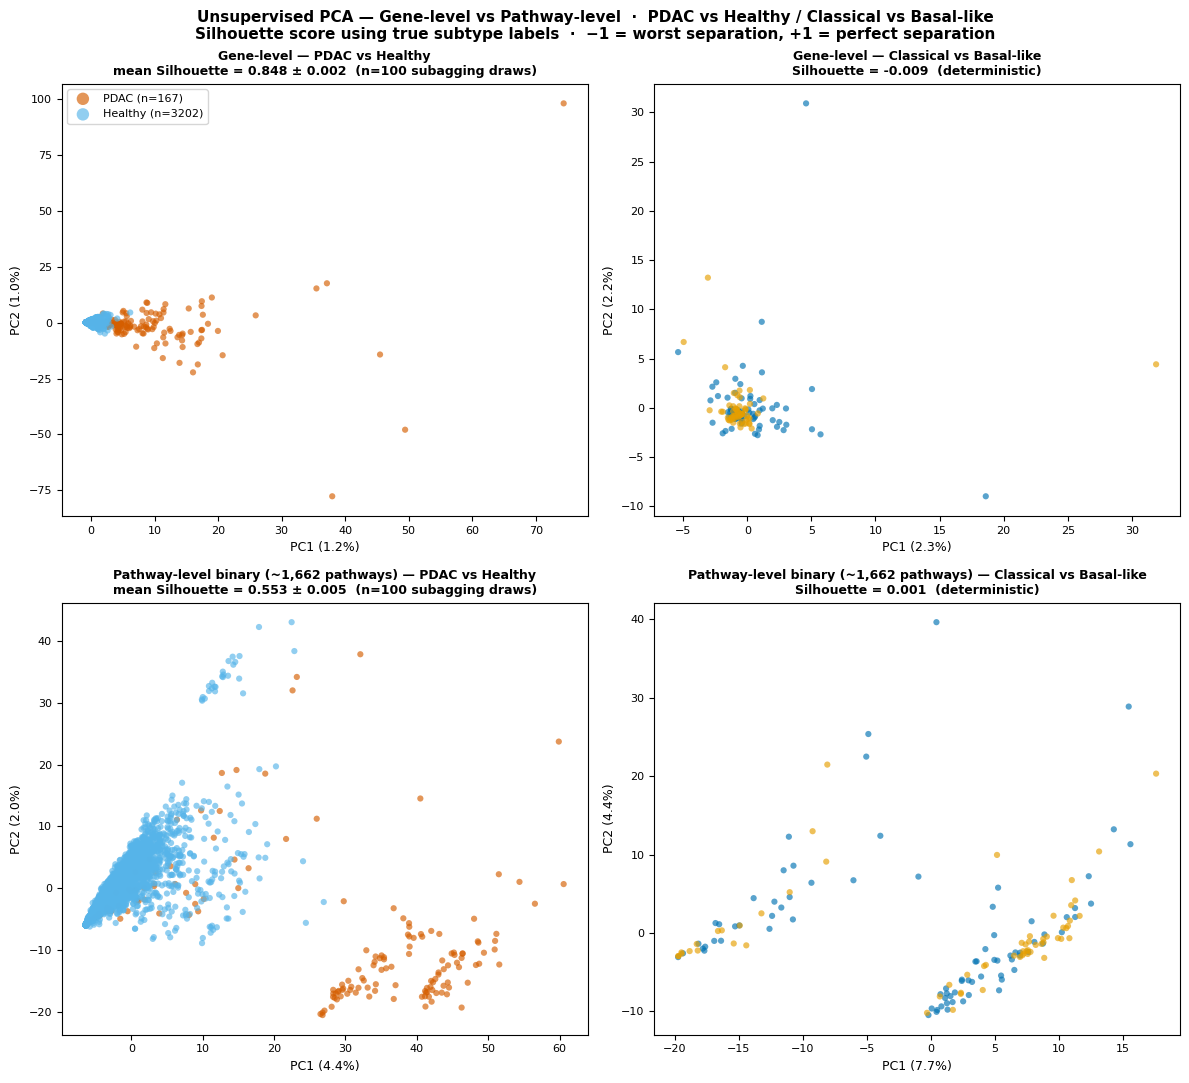

Saved: C:\Users\daane\Desktop\DATA\figures\unsupervised_pca\figure_A_pca_2x2.png


In [9]:
PVH_GROUPS = [
    (1, 'PDAC',    LABEL_COLORS['PDAC']),
    (0, 'Healthy', LABEL_COLORS['Healthy']),
]
CVB_GROUPS = [
    (0, 'Classical',  LABEL_COLORS['Classical']),
    (1, 'Basal-like', LABEL_COLORS['Basal-like']),
]


def plot_pca_panel(ax, X_pca, y_true, evr, groups, title, add_legend=False):
    for cls, name, color in groups:
        m = y_true == cls
        ax.scatter(
            X_pca[m, 0], X_pca[m, 1],
            c=color, label=f'{name} (n={int(m.sum())})',
            s=20, alpha=0.65, edgecolors='none', rasterized=True,
        )
    pc1 = evr[0] * 100
    pc2 = evr[1] * 100
    ax.set_xlabel(f'PC1 ({pc1:.1f}%)', fontsize=9)
    ax.set_ylabel(f'PC2 ({pc2:.1f}%)', fontsize=9)
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.tick_params(labelsize=8)
    if add_legend:
        ax.legend(fontsize=8, markerscale=2, framealpha=0.8)


fig, axes = plt.subplots(2, 2, figsize=(12, 11))

plot_pca_panel(
    axes[0, 0], X_pca_gene_pvh, y_pvh, evr_gene_pvh, PVH_GROUPS,
    f'Gene-level — PDAC vs Healthy\n'
    f'mean Silhouette = {gene_sil_mean:.3f} ± {gene_sil_std:.3f}  (n={N_SUBAGS} subagging draws)',
    add_legend=True,
)
plot_pca_panel(
    axes[0, 1], X_pca_gene_cvb, y_cvb,
    pca_gene_cvb.explained_variance_ratio_, CVB_GROUPS,
    f'Gene-level — Classical vs Basal-like\n'
    f'Silhouette = {sil_gene_cvb:.3f}  (deterministic)',
)
plot_pca_panel(
    axes[1, 0], X_pca_pw_pvh, y_pvh, evr_pw_pvh, PVH_GROUPS,
    f'Pathway-level binary (~{n_pw:,} pathways) — PDAC vs Healthy\n'
    f'mean Silhouette = {pw_sil_mean:.3f} ± {pw_sil_std:.3f}  (n={N_SUBAGS} subagging draws)',
)
plot_pca_panel(
    axes[1, 1], X_pca_pw_cvb, y_cvb,
    pca_pw_cvb.explained_variance_ratio_, CVB_GROUPS,
    f'Pathway-level binary (~{n_pw:,} pathways) — Classical vs Basal-like\n'
    f'Silhouette = {sil_pw_cvb:.3f}  (deterministic)',
)

fig.suptitle(
    'Unsupervised PCA — Gene-level vs Pathway-level  ·  PDAC vs Healthy / Classical vs Basal-like\n'
    'Silhouette score using true subtype labels  ·  −1 = worst separation, +1 = perfect separation',
    fontsize=11, fontweight='bold',
)
plt.tight_layout()
out_path = FIG_DIR / 'figure_A_pca_2x2.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_path.with_suffix('.svg'), bbox_inches='tight')
plt.show()
print(f'Saved: {out_path}')

## 9. Silhouette Summary Table

In [ ]:
rows = [
    {'Feature level': 'Gene-level',          'Task': 'PvH full', 'Mean Silhouette': f'{gene_sil_mean:.3f}', 'Std': f'{gene_sil_std:.3f}', 'n draws': N_SUBAGS},
    {'Feature level': 'Pathway-level binary', 'Task': 'PvH full', 'Mean Silhouette': f'{pw_sil_mean:.3f}',   'Std': f'{pw_sil_std:.3f}',   'n draws': N_SUBAGS},
    {'Feature level': 'Gene-level',          'Task': 'CvB',      'Mean Silhouette': f'{sil_gene_cvb:.3f}', 'Std': '—', 'n draws': 1},
    {'Feature level': 'Pathway-level binary', 'Task': 'CvB',      'Mean Silhouette': f'{sil_pw_cvb:.3f}',  'Std': '—', 'n draws': 1},
]
df_summary = pl.DataFrame(rows)
print(df_summary)

shape: (4, 5)
┌──────────────────────┬──────────┬─────────────────┬───────┬─────────┐
│ Feature level        ┆ Task     ┆ Mean Silhouette ┆ Std   ┆ n draws │
│ ---                  ┆ ---      ┆ ---             ┆ ---   ┆ ---     │
│ str                  ┆ str      ┆ str             ┆ str   ┆ i64     │
╞══════════════════════╪══════════╪═════════════════╪═══════╪═════════╡
│ Gene-level           ┆ PvH full ┆ 0.848           ┆ 0.002 ┆ 100     │
│ Pathway-level binary ┆ PvH full ┆ 0.553           ┆ 0.005 ┆ 100     │
│ Gene-level           ┆ CvB      ┆ -0.009          ┆ —     ┆ 1       │
│ Pathway-level binary ┆ CvB      ┆ 0.001           ┆ —     ┆ 1       │
└──────────────────────┴──────────┴─────────────────┴───────┴─────────┘


: 

## 10. Interpretation

**Gene-level null result (row 1 of Figure A).**
PCA on individual gene-level binary features yields ARI ≈ 0 for both CvB and PvH.
Somatic mutations are too sparse at the single-gene level: most genes are mutated in
only a handful of patients, leaving the matrix with too little shared structure for
unsupervised clustering. Pathway aggregation is necessary to reduce dimensionality to
a regime where clustering becomes possible.

**Pathway-level CvB null result (row 2, col 2 of Figure A).**
Even after aggregating to pathway-level binary features, Classical and Basal-like
patients remain entirely overlapping (ARI ≈ 0, deterministic). The two subtypes share
essentially the same somatic mutation profile at the pathway level. This confirms that
the Classical/Basal-like distinction is transcriptionally — not mutationally — encoded,
and that label supervision is required to extract any discriminative signal.

**Pathway-level PvH signal (row 2, col 1 of Figure A).**
Pathway aggregation does recover separable structure for PDAC vs healthy individuals
(mean ARI > 0 across all 100 subagging draws). PDAC somatic mutations are enriched in
specific pathway families relative to germline variants in healthy individuals, and this
enrichment is sufficiently consistent to be detectable by unsupervised clustering.

**Transition to supervised analysis.**
The null result for CvB at both feature levels motivates a move to supervised LDA with
biology-constrained pathway feature selection (KoCoFX-CB) for the subtype classification
task. The positive PvH result confirms that the mutation signal is real and pathway-level
aggregation is the right scale — further refined in the supervised HvP analysis.